# Exercício

1. Gere uma amostra de tamanho $M$ de uma exponencial através do método de inversão visto em sala. Compare com uma exponencial gerada pelo numpy via histogramas. Comparem também com a densidade real da exponencial $f(x) = \lambda e^{-\lambda x}$ (isto é, seu histograma normalizado tem que ficar igual essa curva).

2. Agora considere $T_n = X_n / n$ onde $X_n$ é uma Geométrica com parâmetro $\lambda/n$. Mostre que quando $n$ é grande, isso se aproxima de uma exponencial.

3. Considere agora $X_1, X_2, \ldots$ variáveis aleatórias i.i.d. com distribuição Exponencial de parâmetro $\lambda$. Vá somando essas variáveis até que a soma ultrapasse $1$ e conte quantas delas foram somadas antes de ultrapassar $1$. Repita esse procedimento $M$ vezes e mostre empiricamente que essa quantidade segue aproximadamente uma Poisson de parâmetro $\lambda$. Compare o histograma obtido com uma Poisson gerada pelo numpy e com a função de probabilidade real da Poisson.

In [73]:
import numpy as np
import matplotlib.pyplot as plt

In [74]:
M = 3000
amostra_exp = []
for i in range(M):
  lamb = 2
  u = np.random.uniform()
  x = - np.log(u)/lamb
  amostra_exp.append(x)

(array([1.612e+03, 7.670e+02, 3.360e+02, 1.460e+02, 8.400e+01, 3.000e+01,
        1.000e+01, 1.000e+01, 4.000e+00, 1.000e+00]),
 array([6.84963513e-05, 1.50818889e+00, 3.01630929e+00, 4.52442969e+00,
        6.03255008e+00, 7.54067048e+00, 9.04879088e+00, 1.05569113e+01,
        1.20650317e+01, 1.35731521e+01, 1.50812725e+01]),
 <BarContainer object of 10 artists>)

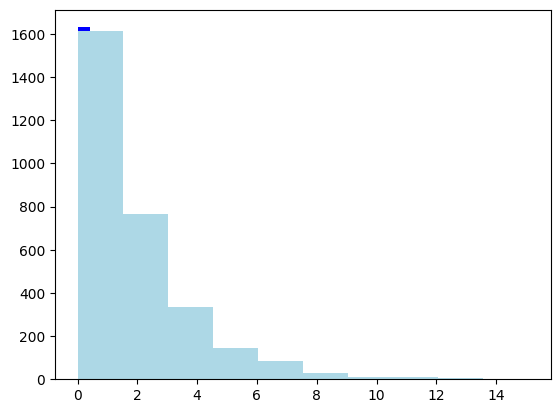

In [75]:
plt.hist(amostra_exp, color = "blue")
plt.hist(np.random.exponential(2,3000), color = "lightblue")


In [76]:
def exponencial(lamb,n):
  amostra = []
  M = 3000
  for i in range(M):
    p = lamb/n
    u = np.random.uniform()
    geo = np.log(1-u)/np.log(1-p)
    t = geo/n
    amostra.append(t)
  return amostra

In [77]:
exp10 = exponencial(2,10)
exp1000 = exponencial(2,1000)
exp100000 = exponencial(2,100000)

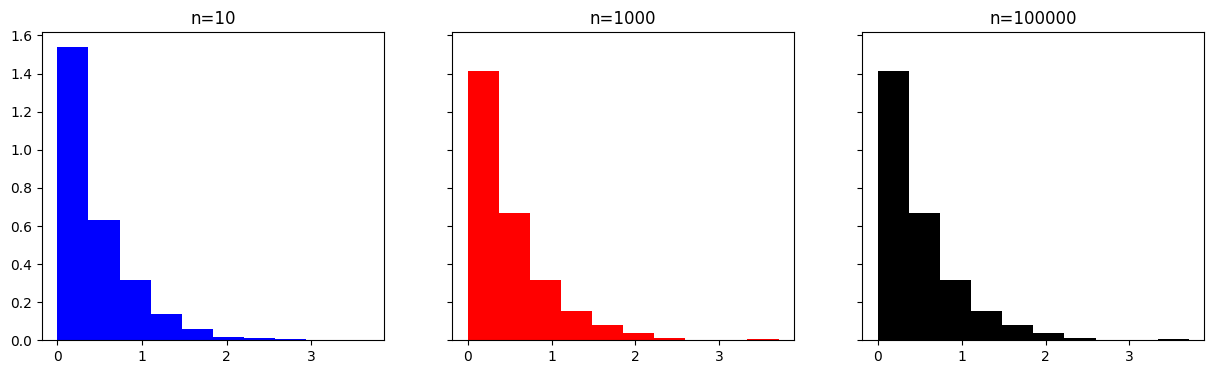

In [78]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

axs[0].hist(exp10, color="blue",density = True)
axs[0].set_title("n=10")

axs[1].hist(exp1000, color="red", density = True)
axs[1].set_title("n=1000")

axs[2].hist(exp1000, color="black", density = True)
axs[2].set_title("n=100000")

plt.show()

In [79]:
poisson_hipotetica = []
M = 5000
for i in range(M):
  soma = 0
  quant = 0
  while soma<1:
    lamb = 2
    u = np.random.uniform()
    x = - np.log(u)/lamb
    soma += x
    quant += 1
  poisson_hipotetica.append(quant)

Text(0.5, 1.0, 'Poisson Numpy')

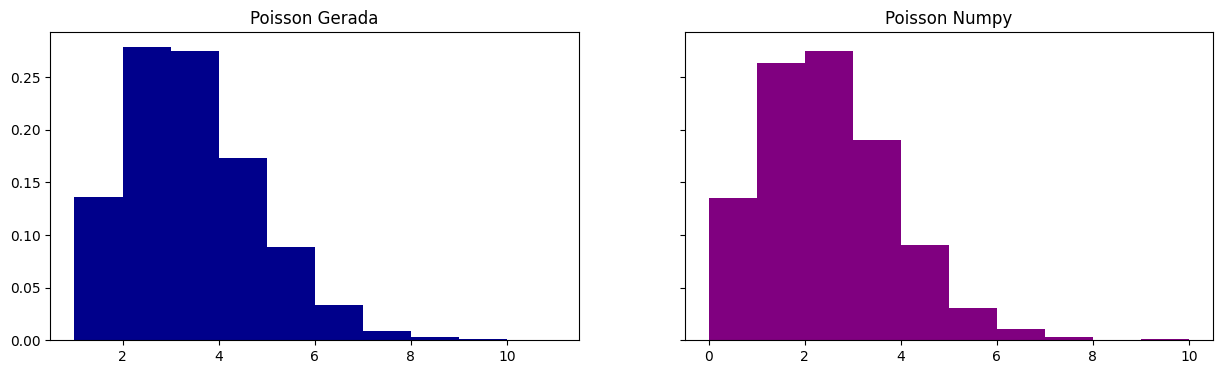

In [80]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4), sharey=True)

axs[0].hist(poisson_hipotetica, density = True, color ="darkblue")
axs[0].set_title("Poisson Gerada")

axs[1].hist(np.random.poisson(2,5000), density=True, color = "purple")
axs[1].set_title("Poisson Numpy")